# Lab 14-13 · GPUs and SIMT

Companion to [chapter 14-13](../../chapters/14-13-gpus-and-simt.md). `simt.py` models a 32-lane warp, memory sectors, shared-memory banks and SM occupancy. Run the cells in order.

In [1]:
import math
import matplotlib.pyplot as plt
import simt

## Part 1 · Divergence

In [2]:
for k in (1, 2, 4, 8, 32):
    prog = [('if', lambda i, k=k: i % k == 0, [('op', 10)], [('op', 10)])]
    print(f'branch on tid % {k:2d}: efficiency {simt.efficiency(prog):.3f}')
print('branch on the warp index (uniform):', simt.efficiency([('if', lambda i: True, [('op', 10)], [('op', 10)])]))
for name, trips in (('tid', lambda i: i), ('tid % 8 + 1', lambda i: i % 8 + 1), ('constant 16', lambda i: 16)):
    print(f'loop trips {name:12s}:', simt.run_warp([('loop', trips, [('op', 1)])]), f'{simt.efficiency([("loop", trips, [("op", 1)])]):.3f}')

branch on tid %  1: efficiency 1.000
branch on tid %  2: efficiency 0.500
branch on tid %  4: efficiency 0.500
branch on tid %  8: efficiency 0.500
branch on tid % 32: efficiency 0.500
branch on the warp index (uniform): 1.0
loop trips tid         : (31, 496) 0.500
loop trips tid % 8 + 1 : (8, 144) 0.562
loop trips constant 16 : (16, 512) 1.000


## Part 2 · Coalescing

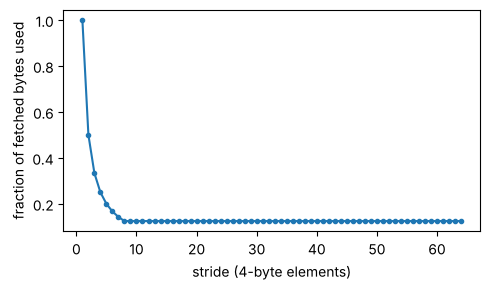

random addresses in 1 MB: 32 sectors


In [3]:
strides = range(1, 65)
sec = [simt.sectors([0x10000 + 4 * s * t for t in range(32)]) for s in strides]
plt.figure(figsize=(5, 3))
plt.plot(list(strides), [128 / (32 * n) for n in sec], marker='.')
plt.xlabel('stride (4-byte elements)'); plt.ylabel('fraction of fetched bytes used'); plt.tight_layout(); plt.show()
import random
rng = random.Random(1)
print('random addresses in 1 MB:', simt.sectors([0x10000 + 4 * rng.randrange(1 << 18) for _ in range(32)]), 'sectors')

## Part 3 · Bank conflicts

**Predict first:** strides 16 and 48.

In [4]:
rows = [(s, simt.bank_conflict([s * t for t in range(32)]), math.gcd(s, 32)) for s in range(1, 65)]
print([r for r in rows if r[1] > 1][:12])
print('all equal gcd:', all(d == g for _, d, g in rows))

[(2, 2, 2), (4, 4, 4), (6, 2, 2), (8, 8, 8), (10, 2, 2), (12, 4, 4), (14, 2, 2), (16, 16, 16), (18, 2, 2), (20, 4, 4), (22, 2, 2), (24, 8, 8)]
all equal gcd: True


## Part 4 · Occupancy

In [5]:
for smem in (0, 16384, 32768, 65536, 98304):
    row = []
    for regs in (16, 32, 48, 64, 96, 128, 255):
        w, lim = simt.occupancy(regs, 256, smem)
        row.append(f'{w:2d}{lim[0]}')
    print(f'smem {smem // 1024:3d} KB:', '  '.join(row))
print('(letter = limiting resource: r registers, s shared memory, w warp slots, b block slots)')

smem   0 KB: 64w  64w  40r  32r  16r  16r   8r
smem  16 KB: 64w  64w  40r  32r  16r  16r   8r
smem  32 KB: 48s  48s  40r  32r  16r  16r   8r
smem  64 KB: 24s  24s  24s  24s  16r  16r   8r
smem  96 KB: 16s  16s  16s  16s  16r  16r   8r
(letter = limiting resource: r registers, s shared memory, w warp slots, b block slots)
